In [2]:
# Initial data
density_TD = 11.31  # [g/cm^3]
Fuel_density = 11.31 * 0.945
equiaxed_density = 0.95 * density_TD
columnar_density = 0.98 * density_TD
DENSITY = [columnar_density, equiaxed_density, Fuel_density]
Pu_concentration = 0.29
O_M = 1.957
x = 2 - O_M
A_value = A_f(x, Pu_concentration)
B_value = B_f(Pu_concentration)
D_value = 5.27e9
E_value = 17109.5

# Data needed for burnup calculation
fuel_outer_diameter = 5.42e-3  # m
fuel_height = 0.85  # m
fuel_density = 11.31 * 0.945 * 1000  # kg/m^3
uptime = 360 * 24 * 3600  # s
q_linear_avg = 38.7e3  # W/m

In [4]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from IPython.display import display, Math

# Definition of symbols for thermal conductivity calculation
T = sp.symbols('T')
A = sp.symbols('A')
B = sp.symbols('B')
D = sp.symbols('D')
E = sp.symbols('E', positive=True)
p = sp.symbols('p')
k = sp.Function('k')(T)

# Function to calculate A depending on x and Pu_concentration
def A_f(x, Pu_concentration):
    A_value = 0.01926 + 1.06e-6 * x + 2.63e-8 * Pu_concentration
    return A_value

# Function to calculate B depending on Pu_concentration
def B_f(Pu_concentration):
    B_value = 2.39e-4 + 1.37e-13 * Pu_concentration
    return B_value

# Function to calculate porosity depending on density
def porosity_f(density_value, density_TD):
    p = 1 - (density_value / density_TD)  # Corrected porosity evaluation
    return p

# Burnup calculation
def bu_function(fuel_outer_diameter, fuel_height, fuel_density, uptime, q_linear_avg):
    Bu = uptime / (24 * 3600) * q_linear_avg * fuel_height / (np.pi * (fuel_outer_diameter / 2)**2 * fuel_height * fuel_density)
    Bu = Bu * 1e-6  # Conversion to GWd/tHM
    return Bu

# Burnup calculation
Burnup = bu_function(fuel_outer_diameter, fuel_height, fuel_density, uptime, q_linear_avg)

# Equation to integrate to obtain thermal conductivity
k_function = sp.Eq(k, 1.755 + (((1 / (A + B * T) + (D / T**2) * sp.exp(-E / T) * (1 - p)**2.5)) - 1.755) * sp.exp(-Burnup / 128.75))
Equation_to_integrate = k_function.rhs

# Symbolic integration
integral_k = sp.integrate(Equation_to_integrate, T)

# Calculation and substitution of values in the matrix cells
moitaiav = []
for rho in DENSITY:
    moitaiav.append(integral_k.subs({
        A: A_value,
        B: B_value,
        D: D_value,
        E: E_value,
        p: porosity_f(rho, density_TD)
    }))

# Displaying results
display(Math(sp.latex(moitaiav[0])))
display(Math(sp.latex(moitaiav[1])))
display(Math(sp.latex(moitaiav[2])))



<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
# Integral calculations
T_f_out = 1600  # max temperature at outer fuel radius
T_equiaxed = 1800  # temperature at equiaxed radius
T_columnar = 2000  # temperature at columnar radius

integral_as_fabricated = - moitaiav[2].subs(T, T_f_out) + moitaiav[2].subs(T, T_equiaxed)
integral_equiaxed = moitaiav[1].subs(T, T_columnar) - moitaiav[1].subs(T, T_equiaxed)

display(Math(r"\text{Integral as fabricated }" + f"{integral_as_fabricated}"))
display(Math(r"\text{Integral equiaxed }" + f"{integral_equiaxed}"))

# Solve for R_equiaxed using equation 2
q_first_avg = 38.7e3

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
R_fuel = 0.542 / 2
# Solve for R_void and R_columnar
R_columnar = sp.Symbol('R_columnar', positive=True)
R_void = sp.Symbol('R_void', positive=True)
display(Math(r"R_{fuel} = " + f"{R_fuel*10}mm"))

<IPython.core.display.Math object>

In [ ]:
eq2 = sp.Eq(integral_as_fabricated, (q_first_avg / (4 * np.pi)) * (1 - (sp.Symbol('R_equiaxed', positive=True) / R_fuel)**2))
R_equiaxed_solution = sp.solve(eq2, sp.Symbol('R_equiaxed', positive=True))
R_equiaxed_value = [sol.evalf() for sol in R_equiaxed_solution if sol.is_real and sol > 0][0]
display(Math(r"R_{equiaxed} = " + f"{R_equiaxed_value*10}mm"))

<IPython.core.display.Math object>

In [ ]:
eq3 = sp.Eq(integral_equiaxed,
        (q_first_avg / (4 * np.pi)) * (equiaxed_density / Fuel_density) * (R_equiaxed_value / R_fuel)**2 * (
        1 - ((equiaxed_density - Fuel_density) / equiaxed_density) * ((R_equiaxed_value / R_columnar)**2)
))
R_columnar_solution = sp.solve(eq3, R_columnar)[0]
display(Math(r"R_{columnar} = " + f"{R_columnar_solution*10}mm"))

<IPython.core.display.Math object>

In [ ]:
eq1 = sp.Eq(np.pi * R_fuel**2 * Fuel_density,
        (np.pi * (R_columnar_solution**2 - R_void**2) * columnar_density +
        np.pi * (R_equiaxed_value**2 - R_columnar_solution**2) * equiaxed_density +
        np.pi * (R_fuel**2 - R_equiaxed_value**2) *  Fuel_density))

R_void_solution = sp.solve(eq1, R_void)[0]
display(Math(r"R_{void} = " + f"{R_void_solution*10}mm"))

<IPython.core.display.Math object>

In [ ]:
Real_fuel = R_fuel*10
Real_equaixed = R_equiaxed_value*10
Real_columnar = R_columnar_solution*10
Real_void = R_void_solution*10

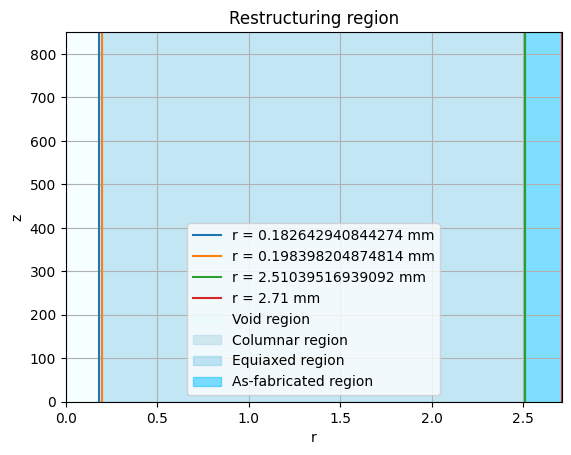

In [ ]:
# Plot the region of the fuel after restructuring
r_values = [Real_void,Real_columnar,Real_equaixed,Real_fuel]
z_range = [0,42.5, 127.5, 212.5, 297.5, 382.5, 467.5, 552.5, 637.5, 722.5, 807.5,850]  # mm

for r in r_values:
    plt.plot([r] * len(z_range), z_range, label=f'r = {r} mm')

# Highlight the area between the two lines
plt.axvspan(0,r_values[0], color='lightcyan', alpha=0.3, label='Void region')
plt.axvspan(r_values[0],r_values[1], color='lightblue',alpha=0.5,label='Columnar region')
plt.axvspan(r_values[1], r_values[2],color='skyblue',alpha=0.5,label='Equiaxed region')
plt.axvspan(r_values[2],r_values[3],color='deepskyblue',alpha=0.5,label='As-fabricated region')

plt.xlim(0, Real_fuel)  # 0 as the lower bound, None for no upper bound
plt.ylim(0,850)

# Graph
plt.xlabel('r')
plt.ylabel('z')
plt.title('Restructuring region')
plt.legend()
plt.grid(True)

# Show graph
plt.show()
